In [45]:
import random
import time

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    device = torch.device('cuda')
else:
    device = torch.device('cpu')

print('Устройство:', device)

Устройство: cuda


In [46]:
DATA_DIR = './data'

raw_train = datasets.CIFAR10(DATA_DIR, train=True, download=True)
raw_test = datasets.CIFAR10(DATA_DIR, train=False, download=True)
class_names = raw_train.classes

print('Классы:', class_names)
print()
print('Картинок в обучающем наборе:', len(raw_train))
print('Картинок в тестовом наборе: ', len(raw_test))
print()
print('Массив с картинками (обучение):', raw_train.data.shape, '- (картинки, высота, ширина, каналы)')
print('Тип пикселей:', raw_train.data.dtype)
print('Меток (обучение):', len(raw_train.targets))

Классы: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']

Картинок в обучающем наборе: 50000
Картинок в тестовом наборе:  10000

Массив с картинками (обучение): (50000, 32, 32, 3) - (картинки, высота, ширина, каналы)
Тип пикселей: uint8
Меток (обучение): 50000


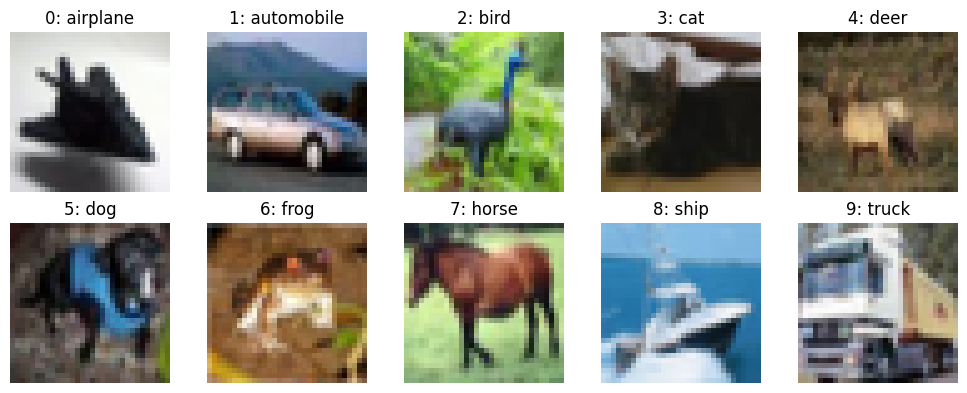

In [47]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4))

for class_id, ax in enumerate(axes.flat):
    first_index = raw_train.targets.index(class_id)
    ax.imshow(raw_train.data[first_index])
    ax.set_title(f'{class_id}: {class_names[class_id]}')
    ax.axis('off')

plt.tight_layout()
plt.show()

In [49]:
VAL_SIZE = 5000

generator = torch.Generator().manual_seed(SEED)
shuffled = torch.randperm(len(raw_train), generator=generator).tolist()
val_idx = shuffled[:VAL_SIZE]
train_idx = shuffled[VAL_SIZE:]

train_images = raw_train.data[train_idx]
mean, std = [], []
for channel in range(3):
    pixels = train_images[..., channel].astype(np.float32) / 255
    mean.append(float(pixels.mean()))
    std.append(float(pixels.std()))

print('Среднее по каналам RGB:', np.round(mean, 4))
print('Std по каналам RGB:    ', np.round(std, 4))

Среднее по каналам RGB: [0.4913 0.4822 0.4466]
Std по каналам RGB:     [0.247  0.2436 0.2617]


In [50]:
train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

eval_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

train_dataset = Subset(datasets.CIFAR10(DATA_DIR, train=True, transform=train_transform), train_idx)
val_dataset = Subset(datasets.CIFAR10(DATA_DIR, train=True, transform=eval_transform), val_idx)
test_dataset = datasets.CIFAR10(DATA_DIR, train=False, transform=eval_transform)

print('Обучение:  ', len(train_dataset), 'картинок')
print('Валидация: ', len(val_dataset), 'картинок')
print('Тест:      ', len(test_dataset), 'картинок')
print()

image, label = train_dataset[0]
print('Форма одного изображения:', tuple(image.shape), '- (каналы, высота, ширина)')
print('Метка одного примера: ', label, f'({class_names[label]})')

Обучение:   45000 картинок
Валидация:  5000 картинок
Тест:       10000 картинок

Форма одного изображения: (3, 32, 32) - (каналы, высота, ширина)
Метка одного примера:  4 (deer)


In [51]:
def conv_bn_relu(in_channels, out_channels):
    return nn.Sequential(
        nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1, bias=False),
        nn.BatchNorm2d(out_channels),
        nn.ReLU(inplace=True),
    )


class SVGG(nn.Module):

    def __init__(self, channels=(64, 128, 256), convs_per_block=2, dropout=0.3, num_classes=10):
        super().__init__()

        layers = []
        in_channels = 3
        for out_channels in channels:
            for _ in range(convs_per_block):
                layers.append(conv_bn_relu(in_channels, out_channels))
                in_channels = out_channels
            layers.append(nn.MaxPool2d(2))
        self.features = nn.Sequential(*layers)

        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Dropout(dropout),
            nn.Linear(in_channels, num_classes),
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)

In [52]:
# Обучение
BATCH_SIZE = 256
EPOCHS = 30
MAX_LR = 0.05
MOMENTUM = 0.9
WEIGHT_DECAY = 7e-4

CHANNELS = (64, 128, 256)
CONVS_PER_BLOCK = 3
DROPOUT = 0.4

NUM_WORKERS = 2

pin = device.type == 'cuda'
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS, pin_memory=pin)
val_loader = DataLoader(val_dataset, batch_size=512, shuffle=False, num_workers=NUM_WORKERS, pin_memory=pin)
test_loader = DataLoader(test_dataset, batch_size=512, shuffle=False, num_workers=NUM_WORKERS, pin_memory=pin)

images, labels = next(iter(train_loader))
print('Одна пачка картинок:', tuple(images.shape), '- (пачка, каналы, высота, ширина)')
print('Одна пачка меток:   ', tuple(labels.shape))

Одна пачка картинок: (256, 3, 32, 32) - (пачка, каналы, высота, ширина)
Одна пачка меток:    (256,)


In [53]:
model = SVGG(channels=CHANNELS, convs_per_block=CONVS_PER_BLOCK, dropout=DROPOUT).to(device)
print(model)

num_params = sum(p.numel() for p in model.parameters())
print(f'\nВсего параметров: {num_params:,}')

with torch.no_grad():
    print('Форма выхода сети для пачки:', tuple(model(images.to(device)).shape))

SVGG(
  (features): Sequential(
    (0): Sequential(
      (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
    )
    (1): Sequential(
      (0): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
    )
    (2): Sequential(
      (0): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
    )
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Sequential(
      (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(128, ep

In [54]:
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.SGD(
    model.parameters(),
    lr=MAX_LR,
    momentum=MOMENTUM,
    weight_decay=WEIGHT_DECAY,
    nesterov=True,
)

scheduler = torch.optim.lr_scheduler.OneCycleLR(
    optimizer,
    max_lr=MAX_LR,
    epochs=EPOCHS,
    steps_per_epoch=len(train_loader),
)

In [55]:
def train_one_epoch(model, loader, criterion, optimizer, scheduler):
    model.train()
    total_loss, correct, total = 0.0, 0, 0

    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        logits = model(images)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()
        scheduler.step()

        total_loss += loss.item() * labels.size(0)
        correct += (logits.argmax(dim=1) == labels).sum().item()
        total += labels.size(0)

    return total_loss / total, correct / total


@torch.no_grad()
def evaluate(model, loader, criterion):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0

    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)

        logits = model(images)
        loss = criterion(logits, labels)

        total_loss += loss.item() * labels.size(0)
        correct += (logits.argmax(dim=1) == labels).sum().item()
        total += labels.size(0)

    return total_loss / total, correct / total

In [56]:
history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}
best_val_acc = 0.0

for epoch in range(1, EPOCHS + 1):
    start_time = time.time()

    train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer, scheduler)
    val_loss, val_acc = evaluate(model, val_loader, criterion)

    history['train_loss'].append(train_loss)
    history['train_acc'].append(train_acc)
    history['val_loss'].append(val_loss)
    history['val_acc'].append(val_acc)

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), 'best_model.pt')

    print(
        f'Эпоха {epoch:2d}/{EPOCHS} | '
        f'обучение: ошибка {train_loss:.4f}, точность {train_acc:.2%} | '
        f'валидация: ошибка {val_loss:.4f}, точность {val_acc:.2%} | '
        f'{time.time() - start_time:.0f} с'
    )

print(f'\nЛучшая точность на валидации: {best_val_acc:.2%}')

Эпоха  1/30 | обучение: ошибка 1.5892, точность 40.92% | валидация: ошибка 1.2363, точность 55.64% | 28 с
Эпоха  2/30 | обучение: ошибка 1.0680, точность 61.89% | валидация: ошибка 1.4994, точность 55.24% | 28 с
Эпоха  3/30 | обучение: ошибка 0.8338, точность 70.75% | валидация: ошибка 0.8211, точность 70.96% | 27 с
Эпоха  4/30 | обучение: ошибка 0.7009, точность 75.62% | валидация: ошибка 1.0637, точность 68.30% | 28 с
Эпоха  5/30 | обучение: ошибка 0.6078, точность 78.93% | валидация: ошибка 0.9142, точность 71.70% | 28 с
Эпоха  6/30 | обучение: ошибка 0.5449, точность 81.33% | валидация: ошибка 0.7343, точность 75.78% | 28 с
Эпоха  7/30 | обучение: ошибка 0.4945, точность 83.05% | валидация: ошибка 0.6399, точность 79.04% | 28 с
Эпоха  8/30 | обучение: ошибка 0.4534, точность 84.47% | валидация: ошибка 0.6601, точность 78.84% | 28 с
Эпоха  9/30 | обучение: ошибка 0.4237, точность 85.35% | валидация: ошибка 0.5228, точность 82.84% | 28 с
Эпоха 10/30 | обучение: ошибка 0.3843, точност

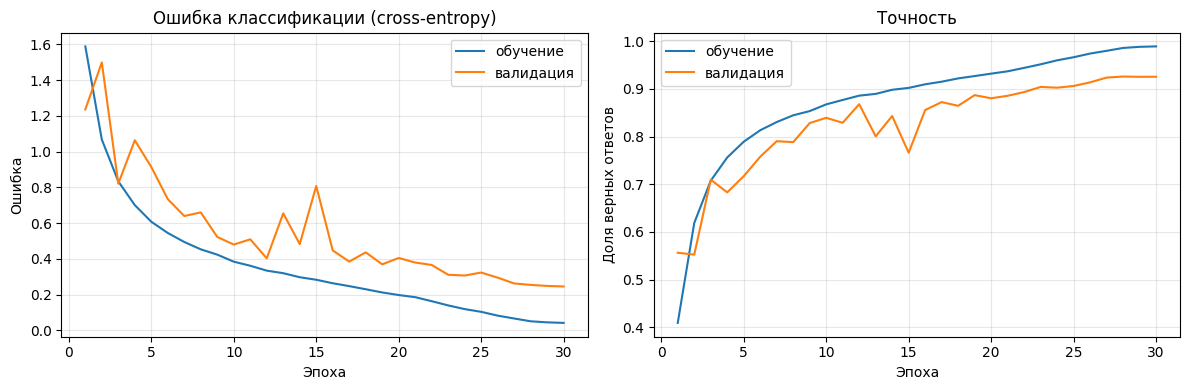

In [57]:
epochs_axis = range(1, EPOCHS + 1)

fig, (ax_loss, ax_acc) = plt.subplots(1, 2, figsize=(12, 4))

ax_loss.plot(epochs_axis, history['train_loss'], label='обучение')
ax_loss.plot(epochs_axis, history['val_loss'], label='валидация')
ax_loss.set_title('Ошибка классификации (cross-entropy)')
ax_loss.set_xlabel('Эпоха')
ax_loss.set_ylabel('Ошибка')
ax_loss.grid(alpha=0.3)
ax_loss.legend()

ax_acc.plot(epochs_axis, history['train_acc'], label='обучение')
ax_acc.plot(epochs_axis, history['val_acc'], label='валидация')
ax_acc.set_title('Точность')
ax_acc.set_xlabel('Эпоха')
ax_acc.set_ylabel('Доля верных ответов')
ax_acc.grid(alpha=0.3)
ax_acc.legend()

plt.tight_layout()
plt.show()

In [58]:
model.load_state_dict(torch.load('best_model.pt', map_location=device))

test_loss, test_acc = evaluate(model, test_loader, criterion)

print('Результат на тестовой выборке')
print(f'  ошибка (cross-entropy):  {test_loss:.4f}')
print(f'  точность:                {test_acc:.2%}')
print(f'  доля неверных ответов:   {1 - test_acc:.2%}')

Результат на тестовой выборке
  ошибка (cross-entropy):  0.2780
  точность:                91.75%
  доля неверных ответов:   8.25%
